In [1]:
import sys
sys.path.append("..")
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

from data.mvtec import MVTecDataset
from models.feature_extractor import PatchFeatureExtractor
from models.patchcore import PatchCoreScorer
from utils.common import load_config

cfg = load_config()
device = "cuda" if torch.cuda.is_available() else "cpu"
root = cfg["paths"]["data_root"]

results = pd.read_csv(cfg["paths"]["results"] / "tables" / "patchcore.csv")
results = results[results["category"] != "mean"].sort_values("image_auroc")
print(results)

      category  image_auroc  pixel_auroc
4         grid     0.915622     0.968870
8         pill     0.940535     0.968096
2      capsule     0.947347     0.983933
9        screw     0.957983     0.989999
14      zipper     0.975315     0.985705
1        cable     0.976762     0.977224
3       carpet     0.978732     0.987319
10        tile     0.980159     0.926784
13        wood     0.985965     0.925757
7    metal_nut     0.993157     0.971185
12  transistor     0.996667     0.969469
5     hazelnut     0.999643     0.982360
6      leather     1.000000     0.989144
0       bottle     1.000000     0.978049
11  toothbrush     1.000000     0.986752


In [2]:
def score_category_detailed(category):
    extractor = PatchFeatureExtractor().to(device).eval()
    bank = np.load(cfg["paths"]["artifacts"] / "banks" / f"{category}.npy")
    scorer = PatchCoreScorer(bank)
    with open(cfg["paths"]["artifacts"] / "stats" / f"{category}.json") as f:
        stats = json.load(f)
    threshold = stats["threshold"]

    ds = MVTecDataset(root, category, "test")
    rows = []
    for i in range(len(ds)):
        item = ds[i]
        defect_type = item["path"].replace("\\", "/").split("/test/")[1].split("/")[0]
        with torch.no_grad():
            patches = extractor.extract_patches(item["image"].unsqueeze(0).to(device)).cpu().numpy()
        score, score_map = scorer.score_image(patches)
        rows.append({
            "idx": i, "path": item["path"], "defect_type": defect_type,
            "label": item["label"], "score": score,
            "predicted": int(score > threshold),
        })
    return pd.DataFrame(rows), threshold

worst_category = results.iloc[0]["category"]
print("worst category:", worst_category)
detail_df, thresh = score_category_detailed(worst_category)
detail_df.head()

worst category: grid


,idx,path,defect_type,label,score,predicted
0,0,C:\Users\mayan\datasets\mvtec_ad\grid\test\ben...,bent,1,1.744175,0
1,1,C:\Users\mayan\datasets\mvtec_ad\grid\test\ben...,bent,1,2.505193,1
2,2,C:\Users\mayan\datasets\mvtec_ad\grid\test\ben...,bent,1,1.884972,0
3,3,C:\Users\mayan\datasets\mvtec_ad\grid\test\ben...,bent,1,2.377305,1
4,4,C:\Users\mayan\datasets\mvtec_ad\grid\test\ben...,bent,1,1.929643,0


In [3]:
summary = detail_df.groupby("defect_type").agg(
    n=("label", "count"),
    mean_score=("score", "mean"),
    correct=("predicted", lambda p: (p == detail_df.loc[p.index, "label"]).mean())
)
print(summary)

                      n  mean_score   correct
defect_type                                  
bent                 12    2.085693  0.416667
broken               12    2.247597  0.666667
glue                 11    1.851195  0.272727
good                 21    1.672545  1.000000
metal_contamination  11    2.139907  0.636364
thread               11    2.084729  0.545455


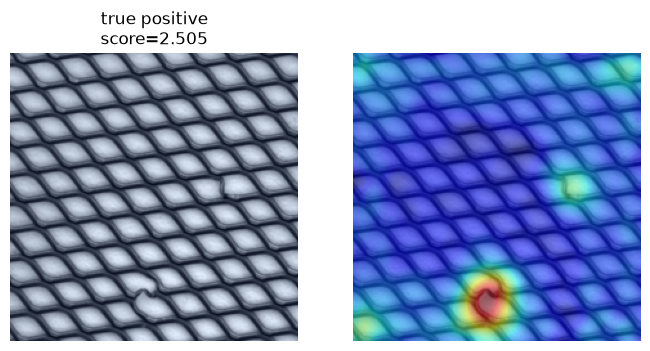

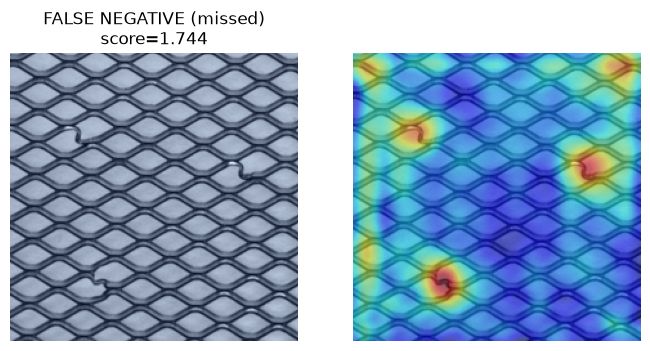

In [4]:
def show_example(idx, category, title):
    ds = MVTecDataset(root, category, "test")
    item = ds[idx]
    img = item["image"].permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min())

    extractor = PatchFeatureExtractor().to(device).eval()
    bank = np.load(cfg["paths"]["artifacts"] / "banks" / f"{category}.npy")
    scorer = PatchCoreScorer(bank)
    with torch.no_grad():
        patches = extractor.extract_patches(item["image"].unsqueeze(0).to(device)).cpu().numpy()
    score, score_map = scorer.score_image(patches)

    fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
    ax[0].imshow(img); ax[0].set_title(f"{title}\nscore={score:.3f}")
    ax[1].imshow(img); ax[1].imshow(score_map, alpha=0.5, cmap="jet")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

# true positive: correctly flagged defect
tp = detail_df[(detail_df.label == 1) & (detail_df.predicted == 1)]
if len(tp): show_example(tp.iloc[0]["idx"], worst_category, "true positive")

# false negative: missed defect
fn = detail_df[(detail_df.label == 1) & (detail_df.predicted == 0)]
if len(fn): show_example(fn.iloc[0]["idx"], worst_category, "FALSE NEGATIVE (missed)")

# false positive: normal image wrongly flagged
fp = detail_df[(detail_df.label == 0) & (detail_df.predicted == 1)]
if len(fp): show_example(fp.iloc[0]["idx"], worst_category, "FALSE POSITIVE")

## Error analysis: grid

`grid` is the weakest category (image AUROC 0.9156, pixel AUROC 0.9688), though
still far above the autoencoder baseline. All 21 normal ("good") test images
were classified correctly — zero false positives. Every error is a false
negative: a real defect that scored below the calibrated threshold (2.0662).

### Per-defect-type breakdown

| defect_type          | n  | mean_score | accuracy |
|-----------------------|----|-----------|----------|
| glue                   | 11 | 1.85      | 27.3%    |
| bent                   | 12 | 2.09      | 41.7%    |
| thread                 | 11 | 2.08      | 54.5%    |
| metal_contamination    | 11 | 2.14      | 63.6%    |
| broken                 | 12 | 2.25      | 66.7%    |
| good (normal)          | 21 | 1.67      | 100%     |

`glue` and `bent` are clearly the hardest defect types for this category,
with correct detection under 50%.

### Why this happens

- **Low-contrast defects.** `glue` is a thin, semi-transparent smear on a
  wire grid — it barely changes local texture compared to something like
  `broken` (a structural break, easier to distinguish).
- **Severity varies within a defect type.** The false-negative example above
  (score 1.744, below the 2.0662 threshold) still shows two visible hot
  spots in its heatmap, comparable to the true-positive example (score
  2.505). The underlying patch distances pick up the distortion correctly —
  it's the single-threshold cutoff that misses it. A mild bend scores lower
  than a severe one, and `mean + 3*std` of normal scores doesn't leave much
  margin for mild cases.
- **One global threshold per category.** Calibration sets a single
  cutoff per category from normal validation images, with no awareness of
  defect type or severity. A defect-type-aware or percentile-based threshold
  could catch more of the `glue`/`bent` cases, at the cost of a higher
  false-positive rate on normals — a precision/recall trade-off, not free.

### Example: false negative (bent, score 1.744)
The heatmap does highlight the bent region (two visible red hotspots), but
the overall max score falls just under the category's threshold — this is a
threshold-sensitivity issue, not a case where the model failed to notice the
defect at all.

### Relation to ablation
The ablation found layer2-only matched layer2+layer3 on bottle,
carpet, screw and metal_nut — but `grid` wasn't in that subset. Given `grid`
is the category needing the most contextual signal to catch subtle defects
like `glue`, it's plausible layer3's broader context matters more here than
it did on the tested subset. Worth re-running the ablation including `grid`
before concluding layer3 is droppable project-wide.